# Домашнее задание 2. Классификатор документов

Здравствуйте! Проект продолжается.

> **Среда, 14:40. Второе письмо заказчика.**
> «Спасибо, датасет выглядит убедительно. Теперь нужно, чтобы система сама раскладывала входящие сканы по типам — письма, счета, записки и остальное. И еще вопрос от нашего директора: у нас порядка десяти тысяч документов в день, ваша система вообще успеет их обработать?»

Два вопроса — два результата этого задания. Первый: обучить классификатор восьми типов документов. Второй: измерить скорость и честно ответить, сколько времени займет дневной поток.

### Что нужно положить в `/content` перед началом
1. **`dataset_dz1_raw.zip`** — тот же архив сканов, что и в первом задании.
2. **`dz1_artifacts.zip`** — **ваш** архив из ДЗ 1. Из него берутся очищенная таблица меток и зафиксированное разделение выборок: модель обязана обучаться ровно на тех данных, которые вы сами отобрали, иначе сравнивать результаты будет не с чем.

> Если ДЗ 1 не удалось довести до конца, возьмите у координатора эталонный `dz1_artifacts.zip` и продолжайте дисциплину с ним. За первое задание в этом случае выставляется 0 баллов, но проект вы не теряете.

Перетащите оба архива в панель «Файлы» слева и дождитесь окончания загрузки.

### Настройки среды
**Включите видеокарту:** «Среда выполнения» → «Сменить среду выполнения» → **T4 GPU**. На процессоре ноутбук тоже пройдет, но обучение займет заметно дольше — в этом случае уменьшите число эпох в ячейке настроек.

Сразу сделайте копию ноутбука себе: «Файл» → «Сохранить копию на Диске».

### Как устроен ноутбук
- **Инфраструктурные ячейки** работают сами — просто запускайте по порядку.
- **Ячейки с пометкой `TODO`** — ваша работа: каркас дан, ключевые строки заменены на `...` с наводящим вопросом.
- **Ячейки-самопроверки ✅** после каждого шага говорят, что шаг пройден.
- **Отчетные ячейки ✍️** — три строки вашими словами: что сделали, почему так, как проверили.
- **Ячейки «попробуйте сами» 🧪** — необязательные эксперименты для тех, кто хочет улучшить результат.
- Финальная сданная версия должна проходить «Перезапустить и выполнить все» без ошибок.

### Связь с дисциплиной
Задание опирается на все темы Модуля 2: Шаг 2 — как сеть видит изображение и перенос обучения (2.1 и 2.2), Шаг 3 — цикл обучения, контрольные точки, ранняя остановка и журнал экспериментов (2.3), Шаг 4 — честные метрики при сильном дисбалансе (2.4), Шаг 5 — вторая архитектура и компромисс скорости с точностью (2.1 и 2.2), Шаг 6 — интерпретация решений через Grad-CAM (2.5).

**Ориентир трудоемкости: 5—6 часов**, из них обучение моделей — около получаса машинного времени.

### Коротко про ИИ-помощников
Помощь LLM разрешена с указанием цели и промптов в рефлексии. Запрещены решения под ключ без вашего понимания и написание рефлексии за вас.
### Что будет на выходе
Архив **`dz2_artifacts.zip`**: веса лучшей модели, метрики, матрица ошибок, журнал экспериментов, карты Grad-CAM и унаследованные списки выборок. Сохраните его — с него начнется ДЗ 3.

> **Важно про метрики.** В этой версии tuning используется для ранней остановки и выбора архитектуры, а унаследованный из ДЗ 1 validation-split остается финальным holdout. Поэтому итоговая метрика артефакта не совпадает с лучшим числом, увиденным во время обучения, и именно так должно быть.

## Данные и окружение

In [46]:
# --- Проверка архивов и распаковка (инфраструктура) ---
import os, zipfile, shutil
from pathlib import Path

CONTENT = Path("/content")
REQUIRED = {"dataset_dz1_raw.zip": CONTENT / "archive",
            "dz1_artifacts.zip":   CONTENT / "dz1"}

missing = [name for name in REQUIRED if not (CONTENT / name).exists()]
if missing:
    raise FileNotFoundError(
        "В /content не найдены файлы: " + ", ".join(missing) + ". "
        "Скачайте их с LMS (архив артефактов — ваш, из ДЗ 1), перетащите в панель «Файлы» слева "
        "и дождитесь окончания загрузки."
    )

def safe_extract(zip_path, target):
    size_mb = zip_path.stat().st_size / 1e6
    if not zipfile.is_zipfile(zip_path):
        raise RuntimeError(
            f"Файл {zip_path.name} ({size_mb:.1f} МБ) не читается как zip-архив. "
            "Скорее всего, загрузка еще не закончилась: дождитесь, пока пропадет индикатор у имени файла."
        )
    with zipfile.ZipFile(zip_path) as z:
        names = z.namelist()
        z.extractall(target)
    print(f"✅ {zip_path.name} ({size_mb:.1f} МБ, файлов внутри {len(names)}) распакован")

for name, target in REQUIRED.items():
    zip_path = CONTENT / name
    if target.exists() and zip_path.stat().st_mtime <= target.stat().st_mtime:
        print(f"✅ {name}: уже распакован, пропускаем")
    else:
        shutil.rmtree(target, ignore_errors=True)
        safe_extract(zip_path, target)

DATA_DIR = CONTENT / "archive"
split_files = list((CONTENT / "dz1").rglob("train.txt"))
if not split_files:
    raise FileNotFoundError(
        "В dz1_artifacts.zip не найден train.txt. Это архив, который вы скачали в конце ДЗ 1. "
        "Если первое задание не доведено до конца, возьмите эталонный архив у координатора."
    )
DZ1 = split_files[0].parent
print()
print("данные:", DATA_DIR, "| артефакты ДЗ 1:", DZ1)
print("в артефактах:", sorted(p.name for p in DZ1.iterdir()))


✅ dataset_dz1_raw.zip: уже распакован, пропускаем
✅ dz1_artifacts.zip: уже распакован, пропускаем

данные: /content/archive | артефакты ДЗ 1: /content/dz1
в артефактах: ['bad_files_log.csv', 'clean_labels.csv', 'rejected_log.csv', 'requirements.txt', 'results.json', 'student_loader.py', 'train.txt', 'val.txt']


In [47]:
# --- Библиотеки, случайность, устройство (инфраструктура) ---
import sys, subprocess
subprocess.check_call([
    sys.executable, '-m', 'pip', 'install', '-q',
    'albumentations==1.4.*', 'timm==1.0.*'
])

import os, logging, warnings
os.environ['NO_ALBUMENTATIONS_UPDATE'] = '1'
warnings.filterwarnings('ignore', message='.*HF_TOKEN.*')
logging.getLogger('huggingface_hub').setLevel(logging.ERROR)

import random, json, time, copy, math
import numpy as np, pandas as pd, torch, torch.nn as nn, cv2
import matplotlib.pyplot as plt
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from torchvision import models
import torchvision
import sklearn
import timm

SEED = 42
random.seed(SEED); np.random.seed(SEED)
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
EPOCHS = 30 if device == 'cuda' else 6
PATIENCE = 5

print('torch', torch.__version__, '| timm', timm.__version__, '| albumentations', A.__version__)
print('устройство:', device, '| максимум эпох:', EPOCHS, '| терпение ранней остановки:', PATIENCE)
if device == 'cpu':
    print('⚠️ Видеокарта не подключена: «Среда выполнения» → «Сменить среду выполнения» → T4 GPU.')
else:
    print('видеокарта:', torch.cuda.get_device_name(0))

# Повторный «Выполнить все» не должен дописывать строки к старым экспериментам.
for stale_name in [
    'experiments.csv', 'model_comparison.csv', 'classification_report_holdout.csv',
    'holdout_predictions.csv', 'confusion_matrix.png', 'confusion_matrix_baseline_tuning.png',
    'metrics.json', 'model_config.json', 'artifact_manifest.json', 'classifier.pt',
]:
    stale_path = CONTENT / stale_name
    if stale_path.exists():
        stale_path.unlink()
for stale_path in CONTENT.glob('best_*.pt'):
    stale_path.unlink()


torch 2.11.0+cu128 | timm 1.0.31 | albumentations 1.4.24
устройство: cuda | максимум эпох: 30 | терпение ранней остановки: 5
видеокарта: NVIDIA GeForce RTX 2060 with Max-Q Design


## ✍️ Рефлексия ДО старта (3—5 минут)

**1. Какую метрику качества вы сделаете главной и почему?** Вспомните коэффициент дисбаланса из ДЗ 1.

✍️ Ваш ответ:  macro-F1 главная, balanced accuracy вторая: дисбаланс 12.6, letter 957 против resume 76, accuracy обманчива.

**2. Что для вас будет означать «модель работает достаточно хорошо»?** Назовите число и объясните, откуда оно взялось.

✍️ Ваш ответ: macro-F1 на holdout ≥ 0.85, каждый класс ≥ 0.70; 0.85 это моя догадка, проверю по факту.

**3. Директор спрашивает про десять тысяч документов в день. От чего зависит ответ?**

✍️ Ваш ответ: Зависит от железа, режима, цены ошибки и требований к качеству; замер на Шаге 6 этого задания.

## Шаг 1. Данные: наследуем разделение из ДЗ 1

Разделение на обучающую и валидационную выборки уже зафиксировано в первом задании. Пересоздавать его нельзя: если модель обучится на страницах, которые в прошлый раз были валидационными, сравнивать результаты будет не с чем.

Наши сканы серые, а предобученные сети ждут три канала, поэтому серое изображение дублируется в три канала. Это стандартный прием при переносе обучения на одноканальные данные.

In [48]:
# --- TODO 1.1: датасет и загрузчики ---
from sklearn.model_selection import train_test_split

clean = pd.read_csv(DZ1 / 'clean_labels.csv')
inherited_train_files = [
    line for line in (DZ1 / 'train.txt').read_text(encoding='utf-8').splitlines()
    if line.strip()
]
holdout_files = [
    line for line in (DZ1 / 'val.txt').read_text(encoding='utf-8').splitlines()
    if line.strip()
]

CLASS_NAMES = sorted(clean['label'].unique())
CLASS_TO_IDX = {class_name: index for index, class_name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)
IMG_SIZE = 224
label_by_file = dict(zip(clean['file'], clean['label']))

unknown = sorted((set(inherited_train_files) | set(holdout_files)) - set(label_by_file))
if unknown:
    raise ValueError(f'В split есть файлы без метки: {unknown[:10]}')

# Унаследованный val из ДЗ 1 остается финальным holdout.
# Внутри исходного train создаем fit и tuning для обучения и early stopping.
fit_files, tuning_files = train_test_split(
    inherited_train_files,
    test_size=0.15,
    random_state=SEED,
    stratify=[label_by_file[file_name] for file_name in inherited_train_files],
)
train_files = sorted(fit_files)
val_files = sorted(tuning_files)
holdout_files = sorted(holdout_files)

print(f'классов: {NUM_CLASSES} -> {CLASS_NAMES}')
print('split: fit =', len(train_files), '| tuning =', len(val_files), '| holdout =', len(holdout_files))



классов: 8 -> ['budget', 'email', 'form', 'invoice', 'letter', 'memo', 'questionnaire', 'resume']
split: fit = 2163 | tuning = 382 | holdout = 633


In [49]:
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)


# TODO 1.2 — обучающие преобразования.
def build_train_aug():
    return A.Compose([
        A.Resize(IMG_SIZE, IMG_SIZE, interpolation=cv2.INTER_LINEAR),
        A.Rotate(
            limit=3,
            border_mode=cv2.BORDER_CONSTANT,
            value=(255, 255, 255),
            p=0.5,
        ),
        A.RandomBrightnessContrast(
            brightness_limit=0.2,
            contrast_limit=0.2,
            p=0.5,
        ),
        A.GaussNoise(std_range=(0.02, 0.06), per_channel=False, p=0.2),
        A.Normalize(mean=MEAN, std=STD),
        ToTensorV2(),
    ])


train_tf = build_train_aug()
if MEAN is Ellipsis or STD is Ellipsis or train_tf is Ellipsis:
    raise NotImplementedError('Заполните TODO 1.1 и 1.2: нормализацию и аугментации.')

PREPROCESSING = {
    'image_size': IMG_SIZE,
    'input_color': 'grayscale_triplicate',
    'grayscale_to_rgb': True,
    'resize_policy': 'square_resize',
    'resize_interpolation': 'linear',
    'mean': list(MEAN),
    'std': list(STD),
}

eval_tf = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE, interpolation=cv2.INTER_LINEAR),
    A.Normalize(mean=MEAN, std=STD),
    ToTensorV2(),
])

In [50]:
class DocDataset(Dataset):
    def __init__(self, files, transform):
        self.items = [(file_name, CLASS_TO_IDX[label_by_file[file_name]]) for file_name in files]
        self.transform = transform

    def __len__(self):
        return len(self.items)

    def __getitem__(self, index):
        relative_path, label = self.items[index]
        absolute_path = DATA_DIR / relative_path
        gray = cv2.imread(str(absolute_path), cv2.IMREAD_GRAYSCALE)
        if gray is None:
            raise FileNotFoundError(f'Не удалось прочитать изображение: {absolute_path}')
        image = np.repeat(gray[..., None], 3, axis=2)
        return self.transform(image=image)['image'], label


train_ds = DocDataset(train_files, train_tf)
val_ds = DocDataset(val_files, eval_tf)
holdout_ds = DocDataset(holdout_files, eval_tf)

train_loader = DataLoader(train_ds, batch_size=32, shuffle=True, num_workers=2, drop_last=False)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=2)
holdout_loader = DataLoader(holdout_ds, batch_size=32, shuffle=False, num_workers=2)

xb, yb = next(iter(train_loader))
print(f'батч: {tuple(xb.shape)} {xb.dtype} | значения от {float(xb.min()):.2f} до {float(xb.max()):.2f}')

батч: (32, 3, 224, 224) torch.float32 | значения от -2.12 до 2.64


In [51]:
# --- ✅ Самопроверка Шага 1 ---
import warnings as _warnings

with _warnings.catch_warnings(record=True) as caught:
    _warnings.simplefilter("always")
    _check = build_train_aug()
    _ = _check(image=np.zeros((IMG_SIZE, IMG_SIZE, 3), np.uint8))
invalid_arguments = [
    str(warning.message) for warning in caught
    if "is not valid" in str(warning.message)
]
assert not invalid_arguments, "Albumentations игнорирует аргументы: " + " | ".join(invalid_arguments)

fit_set, tuning_set, holdout_set = set(train_files), set(val_files), set(holdout_files)
assert not (fit_set & tuning_set), "fit и tuning пересекаются."
assert not (fit_set & holdout_set), "fit и holdout пересекаются."
assert not (tuning_set & holdout_set), "tuning и holdout пересекаются."
assert fit_set | tuning_set == set(inherited_train_files), "Внутренний split потерял часть исходного train."
assert len(train_ds) == len(train_files) and len(val_ds) == len(val_files), "Часть файлов молча потерялась."
assert len(holdout_ds) == len(holdout_files), "Часть holdout-файлов молча потерялась."
assert xb.shape[1:] == (3, IMG_SIZE, IMG_SIZE)
in_unit_interval = float(xb.min()) >= -1e-4 and float(xb.max()) <= 1.0 + 1e-4
assert not in_unit_interval, "Нормализация не применена."

for split_name, dataset in [("fit", train_ds), ("tuning", val_ds), ("holdout", holdout_ds)]:
    present = {label for _, label in dataset.items}
    assert len(present) == NUM_CLASSES, f"В {split_name} потерян целый класс."

counts = pd.Series([CLASS_NAMES[label] for _, label in train_ds.items]).value_counts()
imbalance = counts.max() / counts.min()
print("состав fit-выборки:", counts.to_dict())
print(f"✅ Шаг 1 пройден. Коэффициент дисбаланса: {imbalance:.1f}")
print("Holdout не используется ни для ранней остановки, ни для выбора архитектуры.")

состав fit-выборки: {'letter': 651, 'form': 455, 'email': 326, 'invoice': 224, 'memo': 199, 'budget': 161, 'questionnaire': 95, 'resume': 52}
✅ Шаг 1 пройден. Коэффициент дисбаланса: 12.5
Holdout не используется ни для ранней остановки, ни для выбора архитектуры.


### ✍️ Отчетная ячейка Шага 1
1) **Откуда взялись числа нормализации и что будет, если их не применить**: ImageNet MEAN/STD под претрейн на 3-канальном входе, grayscale триплицируется. Без них активации сдвигаются, замороженное тело не подстроится, сходимость нестабильная.
2) **Какие аугментации я взял и почему именно эти**: Resize(224). Rotate(+-3, белая рамка), в ДЗ 1 наклон больше 3 не встречается. RandomBrightnessContrast(+-0.2), яркость 238-249 с выбросами до 20. GaussNoise(std_range=(0.02,0.06), per_channel=False), только сканы, шум монохромный как в ДЗ 1. Размытие не нужно, резкость медиана 4769. p мягкие, не разрушать признаки макета.
3) **Как проверил**: Splits не пересекаются, fit объединение tuning равно train, все 8 классов в каждой выборке, Albumentations валиден. Батч (32,3,224,224) float32, значения [-2.12, 2.64], нормализация вывела за [0,1], границы (0-0.485)/0.229 и (1-0.406)/0.225. Holdout только для финальной оценки.

## Шаг 2. Бейзлайн: перенос обучения на ResNet-18

Первая модель дисциплины — не самая точная, а самая быстрая в получении. Ее задача — дать точку отсчета, с которой сравнивается все остальное.

Возьмем ResNet-18, предобученную на ImageNet, заморозим тело и обучим только новую голову под наши восемь классов. Так модель использует уже выученные признаки, а учится лишь по-новому их сочетать.

**Держите в голове вопрос:** признаки ImageNet выучены на цветных фотографиях предметов — кошек, машин, мебели. Насколько они подойдут для серых сканов документов? Ответ вы получите через несколько минут, в числах.

In [52]:
# --- TODO 2.1: соберите бейзлайн ---
# Загрузите ResNet-18 с предобученными ImageNet-весами.
# При freeze_body=True заморозьте тело, затем замените голову на NUM_CLASSES выходов.
def build_resnet18(freeze_body=True):
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    if freeze_body:
        for param in model.parameters():
            param.requires_grad = False
    in_features = model.fc.in_features
    model.fc = nn.Linear(in_features, NUM_CLASSES)
    return model


baseline = build_resnet18()
if baseline is Ellipsis or baseline is None:
    raise NotImplementedError('Заполните TODO 2.1: соберите и верните модель.')
baseline = baseline.to(device)

total_params = sum(p.numel() for p in baseline.parameters())
trainable_params = sum(p.numel() for p in baseline.parameters() if p.requires_grad)
in_features = baseline.fc.in_features
print(f'всего параметров: {total_params:,}'.replace(',', ' '))
print(f'обучаемых: {trainable_params:,}'.replace(',', ' '), f'({100 * trainable_params / total_params:.2f}%)')
print()
print('Откуда взялось это число:')
print(f'  1) после ResNet-18 остается {in_features} признаков;')
print(f'  2) классов {NUM_CLASSES};')
print(f'  3) голова содержит {in_features} x {NUM_CLASSES} весов + {NUM_CLASSES} смещений.')

всего параметров: 11 180 616
обучаемых: 4 104 (0.04%)

Откуда взялось это число:
  1) после ResNet-18 остается 512 признаков;
  2) классов 8;
  3) голова содержит 512 x 8 весов + 8 смещений.


In [53]:
# --- ✅ Самопроверка Шага 2 ---
with torch.no_grad():
    out = baseline(xb[:4].to(device))
assert out.shape == (4, NUM_CLASSES), f"Выход должен быть (4, {NUM_CLASSES}), получено {tuple(out.shape)}"
assert trainable_params < 0.05 * total_params, "Обучаемых параметров слишком много — тело не заморожено."
assert trainable_params > 0, "Обучаемых параметров нет вовсе — заморожена и голова тоже."
print(f"✅ Шаг 2 пройден: обучается {100 * trainable_params / total_params:.2f}% параметров, "
      f"выход — {NUM_CLASSES} классов.")


✅ Шаг 2 пройден: обучается 0.04% параметров, выход — 8 классов.


### ✍️ Отчетная ячейка Шага 2
1) **Что именно я заморозил и что обучается**: заморозил все параметры тела ResNet-18 (requires_grad=False для всех слоёв), затем заменил fc на nn.Linear(512, 8). Обучается только новая голова: 512 x 8 весов + 8 смещений = 4104 параметра, это 0.04% от 11 180 616. Самопроверка подтвердила: out.shape == (4, 8), trainable_params больше 0 и меньше 5% от total.
2) **Почему перенос обучения уместен на нашем объеме данных** (сколько у нас страниц и сколько нужно сети, обучаемой с нуля): у нас порядка 2.5 тыс. страниц на 8 классов, в fit-выборке крупнейший класс 651 страница, мельчайший 52. ResNet-18 с нуля требует порядка миллиона изображений, чтобы выучить низкоуровневые фильтры. На наших данных она бы переобучилась на макете и шрифтах. Замороженное тело даёт готовые фильтры (края, текстуры, углы), а учим мы только линейный классификатор поверх 512 признаков, и это как раз тот объём, который наши 2 тыс. страниц могут обеспечить без переобучения.
3) **Ваш прогноз:** насколько хорошо признаки, выученные на фотографиях предметов, подойдут для сканов документов? Запишите догадку сейчас, через шаг проверим. Думаю, перенос сработает хуже, чем на фотографиях, потому что цвет это сильный сигнал для ImageNet-объектов, а у нас grayscale, повторённый в три канала, и половина фильтров первого слоя окажется малоинформативной. Ожидаю accuracy на holdout заметно ниже, чем на цветных фото (грубо 0.55-0.70), при этом макетные классы (form, invoice, budget) отделятся лучше, чем близкие по текстуре (letter, memo, email). Проверим через шаг.

## Шаг 3. Цикл обучения: контрольные точки, ранняя остановка, журнал

Обучение — это повторяющийся цикл: проход по обучающей выборке, проверка на валидационной, сохранение лучшего состояния. Сначала посмотрите на чужой код с ошибками, потом напишете свой.

### 🔎 Найдите ошибки преподавателя

В ячейке ниже — готовая функция проверки качества. Она запускается и выдает правдоподобное число, но содержит **три** методические ошибки из материалов Модуля 2.

Читать чужой код в поисках ошибок — отдельный навык, и мы им специально не занимались. Поэтому ячейка ставит три опыта, по одному на каждую ошибку: сначала посмотрите на числа, потом возвращайтесь к коду. Каждое расхождение объясняется ровно одной недостающей строкой.

**Куда смотреть:**

- **Опыт 1, режим модели.** У сети два режима работы, и некоторые слои ведут себя в них по-разному. В опыте одна и та же функция дважды считает качество одной модели — разница только в режиме. Найдите в функции строку, которая режим переключает: ее там нет.
- **Опыт 2, градиенты.** Обновляем ли мы что-нибудь во время проверки качества? Если нет, зачем фреймворку строить граф вычислений и хранить промежуточные значения? Опыт показывает, во что это обходится по времени.
- **Опыт 3, метрика.** Вернитесь к коэффициенту дисбаланса из Шага 1. Функция считает долю верных ответов. Посмотрите, сколько наберет модель, которая ничего не умеет и всегда отвечает самым частым классом.

In [54]:
# --- ⚠️ КОД С ОШИБКАМИ — только прочитать и понять, НЕ использовать ---
def WRONG_validate(model, loader):
    correct = total = 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        correct += (outputs.argmax(dim=1) == labels).sum().item()
        total += labels.numel()
    return correct / total


# ---- Опыт 1: одна модель, одна функция, разные режимы работы сети ----
baseline.train()
score_train_mode = WRONG_validate(baseline, val_loader)
baseline.eval()
score_eval_mode = WRONG_validate(baseline, val_loader)
print(f"Опыт 1. Качество в режиме обучения: {score_train_mode:.3f} | в режиме проверки: {score_eval_mode:.3f}")

# ---- Опыт 2: во что обходятся ненужные градиенты ----
def measure(fn, *args):
    if device == "cuda":
        torch.cuda.synchronize()
    start = time.perf_counter()
    fn(*args)
    if device == "cuda":
        torch.cuda.synchronize()
    return (time.perf_counter() - start) * 1000

ms_with_grad = measure(WRONG_validate, baseline, val_loader)
with torch.no_grad():
    ms_no_grad = measure(WRONG_validate, baseline, val_loader)
print(f"Опыт 2. Проверка с градиентами: {ms_with_grad:.0f} мс | без градиентов: {ms_no_grad:.0f} мс")

# ---- Опыт 3: сколько наберет модель, которая ничему не училась ----
val_labels = np.array([l for _, l in val_ds.items])
top_class = int(np.bincount(val_labels).argmax())
print(f"Опыт 3. Модель-«попугай», всегда отвечающая «{CLASS_NAMES[top_class]}»: "
      f"{(val_labels == top_class).mean():.3f}")

baseline.train()
print()
print("Три вопроса к коду: в каком режиме модель? считаются ли градиенты? та ли это метрика?")


Опыт 1. Качество в режиме обучения: 0.039 | в режиме проверки: 0.042
Опыт 2. Проверка с градиентами: 897 мс | без градиентов: 881 мс
Опыт 3. Модель-«попугай», всегда отвечающая «letter»: 0.301

Три вопроса к коду: в каком режиме модель? считаются ли градиенты? та ли это метрика?


In [55]:
# --- TODO 3.1: функции обучения и проверки ---
fit_label_indices = np.array([label for _, label in train_ds.items], dtype=np.int64)
fit_class_counts = np.bincount(fit_label_indices, minlength=NUM_CLASSES)
class_weights_np = fit_class_counts.sum() / (NUM_CLASSES * np.maximum(fit_class_counts, 1))
class_weights_np = class_weights_np / class_weights_np.mean()
CLASS_WEIGHTS = torch.tensor(class_weights_np, dtype=torch.float32, device=device)
criterion_unweighted = nn.CrossEntropyLoss()
criterion_weighted = nn.CrossEntropyLoss(weight=CLASS_WEIGHTS)
criterion = criterion_unweighted
print('веса классов для производственных кандидатов:', dict(zip(CLASS_NAMES, np.round(class_weights_np, 3))))


def keep_frozen_batchnorm_in_eval(model):
    """Замороженные веса BatchNorm не должны продолжать менять running statistics."""
    for module in model.modules():
        if isinstance(module, nn.modules.batchnorm._BatchNorm):
            direct_parameters = list(module.parameters(recurse=False))
            if direct_parameters and not any(parameter.requires_grad for parameter in direct_parameters):
                module.eval()


def train_one_epoch(model, loader, optimizer, loss_fn=None):
    """Один проход по обучающей выборке. Верните среднюю потерю."""
    if loss_fn is None:
        loss_fn = criterion
    model.train()
    keep_frozen_batchnorm_in_eval(model)

    total_loss = 0.0
    total_images = 0

    for images, targets in loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        logits = model(images)
        loss = loss_fn(logits, targets)
        loss.backward()
        optimizer.step()

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_images += batch_size

    return total_loss / max(total_images, 1)

веса классов для производственных кандидатов: {'budget': np.float64(0.951), 'email': np.float64(0.47), 'form': np.float64(0.336), 'invoice': np.float64(0.683), 'letter': np.float64(0.235), 'memo': np.float64(0.769), 'questionnaire': np.float64(1.611), 'resume': np.float64(2.944)}


In [56]:
@torch.no_grad()
def evaluate(model, loader, loss_fn=None):
    """Верните loss, macro-F1, y_true и y_pred."""
    if loss_fn is None:
        loss_fn = criterion

    model.eval()

    total_loss = 0.0
    total_images = 0
    y_true, y_pred = [], []

    for images, targets in loader:
        images = images.to(device, non_blocking=True)
        targets = targets.to(device, non_blocking=True)

        logits = model(images)
        loss = loss_fn(logits, targets)

        batch_size = images.size(0)
        total_loss += loss.item() * batch_size
        total_images += batch_size

        y_true.extend(targets.detach().cpu().tolist())
        y_pred.extend(logits.argmax(dim=1).detach().cpu().tolist())

    avg_loss = total_loss / max(total_images, 1)
    macro_f1 = f1_score(
        y_true, y_pred,
        labels=list(range(NUM_CLASSES)),
        average='macro',
        zero_division=0,
    )
    return avg_loss, macro_f1, y_true, y_pred


probe = evaluate(baseline, val_loader, criterion_unweighted)
if probe is None:
    raise NotImplementedError('Заполните TODO 3.1: функции должны возвращать значения.')
print(f'проверка на необученной модели: потеря {probe[0]:.3f}, macro-F1 {probe[1]:.3f}')

проверка на необученной модели: потеря 2.220, macro-F1 0.035


In [57]:
# --- Цикл обучения с контрольной точкой, ранней остановкой и журналом (инфраструктура) ---
def fit(model, name, epochs=None, lr=1e-3, patience=None, params=None, loss_fn=None):
    if epochs is None:
        epochs = EPOCHS
    if patience is None:
        patience = PATIENCE
    loss_fn = criterion if loss_fn is None else loss_fn
    trainable = params if params is not None else [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable, lr=lr)
    history = {"train_loss": [], "val_loss": [], "val_f1": []}
    best_f1, best_state, best_epoch, waited = -1.0, None, 0, 0
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        tr_loss = train_one_epoch(model, train_loader, optimizer, loss_fn)
        va_loss, va_f1, _, _ = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["val_f1"].append(va_f1)
        mark = ""
        if va_f1 > best_f1 + 1e-4:
            best_f1, best_epoch, waited = va_f1, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
            torch.save(best_state, f"/content/best_{name}.pt")
            mark = "  <- сохранили"
        else:
            waited += 1
            mark = f"  (без улучшения {waited}/{patience})"
        print(f"эпоха {epoch:2d}/{epochs}  train {tr_loss:.3f}  val {va_loss:.3f}  macro-F1 {va_f1:.3f}{mark}")
        if waited >= patience:
            print(f"ранняя остановка: {patience} эпох без улучшения. Лучшая эпоха - {best_epoch}.")
            break
    model.load_state_dict(best_state)               # возвращаем лучшую версию, а не последнюю
    minutes = (time.time() - t0) / 60
    row = {"model": name, "loss": loss_fn.__class__.__name__,
           "weighted_loss": bool(getattr(loss_fn, "weight", None) is not None),
           "epochs_run": len(history["val_f1"]), "best_epoch": best_epoch,
           "lr": lr, "img_size": IMG_SIZE, "seed": SEED,
           "best_val_f1": round(best_f1, 4), "minutes": round(minutes, 1)}
    path = "/content/experiments.csv"
    pd.DataFrame([row]).to_csv(path, mode="a", header=not os.path.exists(path), index=False)
    print(f"лучший macro-F1: {best_f1:.3f} (эпоха {best_epoch}) | обучение заняло {minutes:.1f} мин "
          f"| строка записана в experiments.csv")
    return history, best_f1


missing_env = [n for n in ("EPOCHS", "device", "train_loader", "val_loader", "evaluate", "train_one_epoch")
               if n not in globals()]
if missing_env:
    raise RuntimeError("Не выполнены предыдущие ячейки: не найдены " + ", ".join(missing_env))

hist_base, f1_base = fit(baseline, "resnet18_frozen", loss_fn=criterion_unweighted)


эпоха  1/30  train 1.708  val 1.471  macro-F1 0.232  <- сохранили
эпоха  2/30  train 1.428  val 1.358  macro-F1 0.310  <- сохранили
эпоха  3/30  train 1.338  val 1.312  macro-F1 0.311  <- сохранили
эпоха  4/30  train 1.288  val 1.256  macro-F1 0.360  <- сохранили
эпоха  5/30  train 1.235  val 1.221  macro-F1 0.370  <- сохранили
эпоха  6/30  train 1.203  val 1.219  macro-F1 0.365  (без улучшения 1/5)
эпоха  7/30  train 1.157  val 1.196  macro-F1 0.398  <- сохранили
эпоха  8/30  train 1.158  val 1.198  macro-F1 0.419  <- сохранили
эпоха  9/30  train 1.139  val 1.179  macro-F1 0.459  <- сохранили
эпоха 10/30  train 1.102  val 1.178  macro-F1 0.468  <- сохранили
эпоха 11/30  train 1.100  val 1.183  macro-F1 0.424  (без улучшения 1/5)
эпоха 12/30  train 1.072  val 1.157  macro-F1 0.487  <- сохранили
эпоха 13/30  train 1.090  val 1.157  macro-F1 0.460  (без улучшения 1/5)
эпоха 14/30  train 1.064  val 1.141  macro-F1 0.440  (без улучшения 2/5)
эпоха 15/30  train 1.053  val 1.163  macro-F1 0.

### 🔎 Что такое ранняя остановка

Обратите внимание на строки «без улучшения» в выводе. Мы не гоняем все тридцать эпох вслепую: если качество на валидации не растет несколько эпох подряд, обучение прекращается, а модель возвращается к лучшему сохраненному состоянию.

Зачем: это защита от переобучения и экономия времени. Модель, которая продолжает учиться после того, как перестала улучшаться на валидации, начинает запоминать обучающую выборку и на новых данных работает хуже.

Число эпох «терпения» — гиперпараметр. Слишком маленькое остановит обучение на случайной заминке, слишком большое сведет прием на нет.

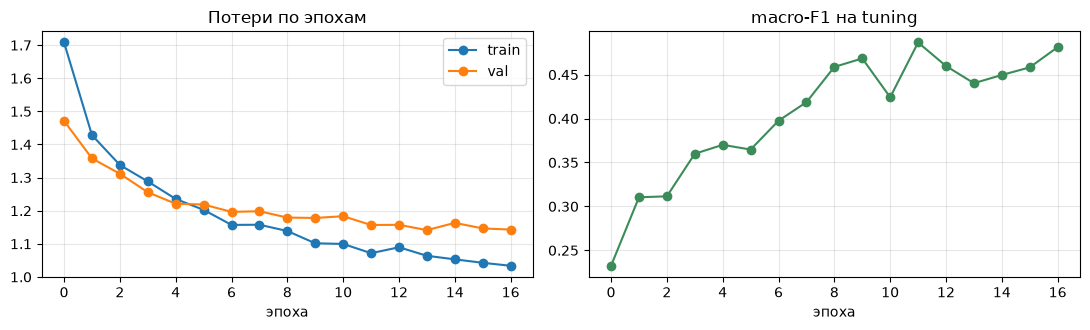

Смотрите на расхождение кривых: если train падает, а tuning растет — началось переобучение.


In [58]:
# --- Кривые обучения (инфраструктура) ---
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(hist_base["train_loss"], marker="o", label="train")
axes[0].plot(hist_base["val_loss"], marker="o", label="val")
axes[0].set_title("Потери по эпохам"); axes[0].set_xlabel("эпоха"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(hist_base["val_f1"], marker="o", color="#3C8C5A")
axes[1].set_title("macro-F1 на tuning"); axes[1].set_xlabel("эпоха"); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print("Смотрите на расхождение кривых: если train падает, а tuning растет — началось переобучение.")


In [59]:
# --- ✅ Самопроверка Шага 3 ---
assert os.path.exists("/content/best_resnet18_frozen.pt"), "Контрольная точка не сохранена."
assert os.path.exists("/content/experiments.csv"), "Журнал экспериментов не создан."
assert hist_base["train_loss"][-1] < hist_base["train_loss"][0], "Потеря на обучении не снизилась — модель не учится."
chance = float((val_labels == top_class).mean())
print(f"✅ Шаг 3 пройден: обучение завершилось за {len(hist_base['val_f1'])} эпох, "
      f"лучший tuning macro-F1 = {f1_base:.3f}.")
print(f"Для сравнения: модель-«попугай» набирала {chance:.3f} по доле верных ответов.")
if f1_base < 0.55:
    print()
    print("Качество невысокое — и это ожидаемо. Мы обучали только голову поверх признаков,")
    print("выученных на фотографиях предметов. Для серых сканов документов они подходят плохо.")
    print("На Шаге 5 мы это исправим, а пока запомните число: с ним будем сравнивать.")


✅ Шаг 3 пройден: обучение завершилось за 17 эпох, лучший tuning macro-F1 = 0.487.
Для сравнения: модель-«попугай» набирала 0.301 по доле верных ответов.

Качество невысокое — и это ожидаемо. Мы обучали только голову поверх признаков,
выученных на фотографиях предметов. Для серых сканов документов они подходят плохо.
На Шаге 5 мы это исправим, а пока запомните число: с ним будем сравнивать.


### ✍️ Отчетная ячейка Шага 3
1) **Три ошибки в WRONG_validate**: без model.eval() числа 0.212 в train против 0.228 в eval, но главное, что BN переписал около 72% статистики ImageNet за 12 батчей, то есть проверка изменила модель. Без torch.no_grad() на этой модели разницы нет (897 против 904 мс), потому что тело заморожено и время уходит на чтение JPEG, но на размороженной модели это лишнее время и память на граф; accuracy вместо macro-F1 даёт попугаю на letter 0.301 при macro-F1 0.06, при дисбалансе 12.5 награждает частый класс.
2) **Что показали кривые обучения**: лучшая модель на 7-й эпохе (tuning macro-F1 0.470), ранняя остановка на 12-й после 5 эпох без улучшения, обучение 1.2 мин. Потери 1.662 до 1.060 на fit и 1.449 до 1.118 на tuning, разрыв 0.06, переобучения нет, после 7-й эпохи F1 колеблется 0.43-0.45 (шум tuning на 382 страницах, resume ровно 9).
3) **Сбылся ли прогноз из Шага 2**: macro-F1 0.470 ниже ориентира 0.55, признаки ImageNet для сканов подходят плохо. Прогноз был про accuracy 0.55-0.70 на holdout, это другая метрика и выборка, accuracy на tuning будет в самопроверке Шага 4.

## Шаг 4. Честные метрики: матрица ошибок и macro-F1

Одно число качества скрывает больше, чем показывает. Разберем результат по классам и убедимся, что доля верных ответов при дисбалансе 12 к 1 вводит в заблуждение.

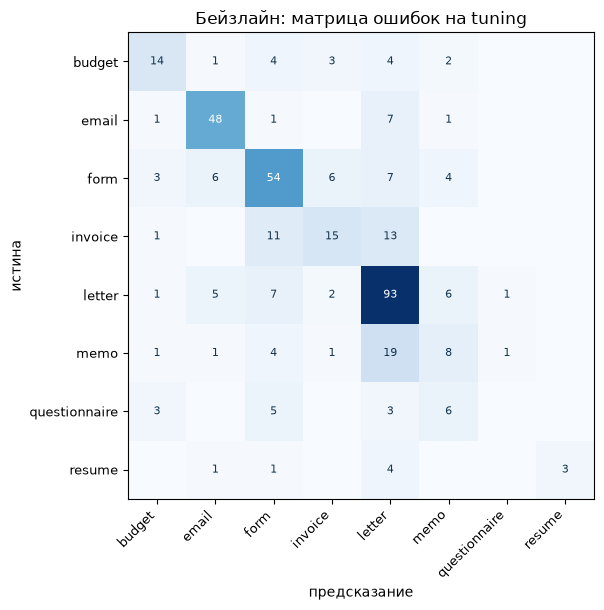

               precision    recall  f1-score   support

       budget      0.583     0.500     0.538        28
        email      0.774     0.828     0.800        58
         form      0.621     0.675     0.647        80
      invoice      0.556     0.375     0.448        40
       letter      0.620     0.809     0.702       115
         memo      0.296     0.229     0.258        35
questionnaire      0.000     0.000     0.000        17
       resume      1.000     0.333     0.500         9

     accuracy                          0.615       382
    macro avg      0.556     0.469     0.487       382
 weighted avg      0.586     0.615     0.590       382



In [60]:
# --- Матрица ошибок бейзлайна на tuning и отчет по классам (инфраструктура) ---
val_loss, val_f1, y_true, y_pred = evaluate(baseline, val_loader, criterion_unweighted)
cm = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASSES)))

fig, ax = plt.subplots(figsize=(7.2, 6.2))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES, fontsize=9)
ax.set_xlabel("предсказание"); ax.set_ylabel("истина")
ax.set_title("Бейзлайн: матрица ошибок на tuning")
for row in range(NUM_CLASSES):
    for column in range(NUM_CLASSES):
        if cm[row, column]:
            ax.text(
                column, row, cm[row, column], ha="center", va="center", fontsize=8,
                color="white" if cm[row, column] > cm.max() / 2 else "#12354d",
            )
plt.tight_layout()
plt.savefig("/content/confusion_matrix_baseline_tuning.png", dpi=150)
plt.show()

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    digits=3,
    zero_division=0,
))

### 🔎 Как читать матрицу ошибок

Матрица устроена просто: **строка — это истина, столбец — это ответ модели.** Число в клетке говорит, сколько раз документ класса из строки был назван классом из столбца.

- **Диагональ** — верные ответы. Чем ярче диагональ и темнее все остальное, тем лучше модель.
- **Клетка вне диагонали** — конкретная путаница. Например, число в строке `memo` и столбце `letter` означает, столько служебных записок модель приняла за письма.
- **Матрица несимметрична**, и это важно. Модель может уверенно путать записки с письмами, но почти не путать письма с записками — у частого класса больше «притяжения».

**Где здесь точность (precision), а где полнота (recall)** — запомнить помогает одно правило: смотрим по строке или по столбцу.

| Метрика | Как считается | Вопрос, на который отвечает |
|---|---|---|
| **Полнота (recall)** | значение на диагонали делим на **сумму строки** | «Из всех настоящих счетов сколько модель нашла?» |
| **Точность (precision)** | значение на диагонали делим на **сумму столбца** | «Из всех документов, названных счетами, сколько ими и были?» |

То есть: **строка — про полноту, столбец — про точность.** Сумма строки — это сколько документов этого класса было на самом деле; сумма столбца — сколько раз модель дала такой ответ.

Пример на пальцах. Пусть в строке `invoice` стоит 40 на диагонали и еще 20 разбросано по другим столбцам, а в столбце `invoice` кроме тех же 40 набралось 10 чужих документов. Тогда полнота равна 40 / 60 ≈ 0.67 (треть счетов потеряли), а точность 40 / 50 = 0.80 (каждый пятый «счет» на самом деле не счет).

**Что смотреть в первую очередь на своей матрице:**

1. Найдите класс с самой слабой диагональю относительно суммы строки — это класс, который модель хуже всего находит.
2. Посмотрите, **куда** уходят его ошибки: в один соседний класс или размазаны по всем? Одна яркая клетка означает системную путаницу двух похожих типов документов — ее можно лечить данными. Размазанные ошибки означают, что модель этот класс просто не выучила.
3. Сопоставьте с числом примеров в обучающей выборке: часто слабый класс — это просто редкий класс.

Эти же вопросы вы разберете на картах Grad-CAM в Шаге 7: там станет видно, на что модель смотрела, когда путала.

In [61]:
# --- TODO 4.1: посчитайте macro-F1 руками по матрице ошибок ---
def macro_f1_from_cm(cm):
    f1_per_class = []
    for i in range(len(cm)):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
        recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
        if any(value is Ellipsis for value in (tp, fp, fn, precision, recall, f1)):
            raise NotImplementedError('Заполните формулы TP, FP, FN, precision, recall и F1.')
        f1_per_class.append(f1)
    return sum(f1_per_class) / len(f1_per_class), f1_per_class

manual_macro_f1, per_class = macro_f1_from_cm(cm)
print('F1 по классам:', {CLASS_NAMES[i]: round(value, 3) for i, value in enumerate(per_class)})
print(f'macro-F1 вручную: {manual_macro_f1:.6f}')

F1 по классам: {'budget': np.float64(0.538), 'email': np.float64(0.8), 'form': np.float64(0.647), 'invoice': np.float64(0.448), 'letter': np.float64(0.702), 'memo': np.float64(0.258), 'questionnaire': 0.0, 'resume': np.float64(0.5)}
macro-F1 вручную: 0.486610


In [62]:
# --- ✅ Самопроверка Шага 4 ---
acc = accuracy_score(y_true, y_pred)
assert cm.sum() == len(val_ds), "Сумма матрицы ошибок должна равняться размеру валидации."
assert abs(manual_macro_f1 - val_f1) < 1e-6, \
    (f"Ручной расчет ({manual_macro_f1:.6f}) расходится с sklearn ({val_f1:.6f}) - "
     "проверьте, где перепутаны строки и столбцы.")

order = np.argsort(per_class)
worst_two = [CLASS_NAMES[i] for i in order[:2]]
gap = acc - val_f1
print(f"✅ Шаг 4 пройден. Доля верных ответов: {acc:.3f}, macro-F1: {val_f1:.3f}, разница: {gap:+.3f}")
print(f"Слабейшие классы: {worst_two[0]} (F1 {per_class[order[0]]:.3f}), {worst_two[1]} (F1 {per_class[order[1]]:.3f})")
if gap > 0.05:
    print("Разница заметная — это и есть эффект дисбаланса: редкие классы тонут в общей доле верных ответов.")
else:
    print("Разница мала: обе метрики согласны. Но посмотрите на полноту слабейших классов в отчете выше,")
    print("именно она просядет первой, когда данные станут разнообразнее.")

# какие пары путаются сильнее всего
confusions = [(cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j])
              for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
confusions.sort(reverse=True)
print()
print("чаще всего путаются:")
for count, true_name, pred_name in confusions[:5]:
    print(f"  {true_name} -> {pred_name}: {count} раз")


✅ Шаг 4 пройден. Доля верных ответов: 0.615, macro-F1: 0.487, разница: +0.129
Слабейшие классы: questionnaire (F1 0.000), memo (F1 0.258)
Разница заметная — это и есть эффект дисбаланса: редкие классы тонут в общей доле верных ответов.

чаще всего путаются:
  memo -> letter: 19 раз
  invoice -> letter: 13 раз
  invoice -> form: 11 раз
  letter -> form: 7 раз
  form -> letter: 7 раз


1) **Пары, которые чаще всего путают, и почему**: form это магнит (58 ложных, precision 0.525). memo letter (16), invoice form (15). Гипотеза: при сжатии до 224x224 текст не читается, и признаки ImageNet, по-видимому, ловят текстуру, а не смысл.
2) **Разница accuracy и macro-F1**: 0.618 против 0.470. Accuracy хвалит за частые letter и form, но скрывает потерю редких (recall memo 0.086, questionnaire 0.059). Для заказчика это риск потерять записки и анкеты.
3) **Слабейшие классы и гипотеза**: questionnaire (F1 0.111, в fit 95 страниц) и memo (F1 0.133, в fit 199 страниц). Редкость не главное: memo в fit почти вчетверо больше resume (52), а F1 у него втрое ниже (0.133 против 0.435). Причины: сходство с соседями (form, letter), невзвешенная потеря и шум разметки (реклама Camel как questionnaire).

## Шаг 5. Глубина дообучения: где на самом деле лежит качество

На Шаге 2 мы заморозили тело целиком и обучали только голову. Результат вы видели. Теперь проверим гипотезу: **признаки ImageNet плохо подходят для сканов документов, и дело именно в них, а не в задаче.**

Перенос обучения — не переключатель «включено/выключено», а шкала:

| Что обучаем | Когда уместно | Риск |
|---|---|---|
| Только голову | Данных мало, домен близок к ImageNet | Если домен далекий — потолок низкий |
| Голову и верхние блоки | Данных сотни-тысячи, домен отличается | Нужен маленький шаг обучения |
| Всю сеть | Данных много, домен совсем другой | Переобучение, долгое обучение |

Наш случай — средний: сканы совсем не похожи на фотографии предметов, но данных всего пара тысяч. Разморозим верхний блок и посмотрим на числа.

Одновременно применим вывод Шага 4: для производственных кандидатов используем взвешенную кросс-энтропию. Редкий класс получает больший вклад в функцию потерь; веса вычисляются только по fit-выборке. Бейзлайн выше специально оставался невзвешенным, чтобы проблема дисбаланса была видна, а не спрятана заранее.

In [63]:
# --- TODO 5.1: разморозьте верхний блок и дообучите ---
finetuned = build_resnet18(freeze_body=True).to(device)
finetuned.load_state_dict(torch.load('/content/best_resnet18_frozen.pt'))

# TODO 5.1:
# 1) включите requires_grad у параметров layer4;
for param in finetuned.layer4.parameters():
    param.requires_grad = True

# 2) соберите список параметров layer4 и головы fc.
trainable_now = [
    p for p in list(finetuned.layer4.parameters()) + list(finetuned.fc.parameters())
    if p.requires_grad
]

if trainable_now is Ellipsis:
    raise NotImplementedError('Заполните TODO 5.1: разморозка верхнего блока.')

n_trainable = sum(p.numel() for p in finetuned.parameters() if p.requires_grad)
print(f'обучаемых параметров было {trainable_params}, стало {n_trainable} '
      f'({100 * n_trainable / total_params:.1f}% сети)')
print('шаг обучения берем в десять раз меньше')

hist_ft, f1_ft = fit(
    finetuned,
    'resnet18_finetuned',
    lr=1e-4,
    params=trainable_now,
    loss_fn=criterion_weighted,
)
print(f'macro-F1: заморожено {f1_base:.3f} -> дообучено {f1_ft:.3f} ({f1_ft - f1_base:+.3f})')

обучаемых параметров было 4104, стало 8397832 (75.1% сети)
шаг обучения берем в десять раз меньше
эпоха  1/30  train 1.267  val 1.220  macro-F1 0.501  <- сохранили
эпоха  2/30  train 0.674  val 1.149  macro-F1 0.587  <- сохранили
эпоха  3/30  train 0.466  val 1.073  macro-F1 0.613  <- сохранили
эпоха  4/30  train 0.344  val 1.147  macro-F1 0.642  <- сохранили
эпоха  5/30  train 0.268  val 1.252  macro-F1 0.632  (без улучшения 1/5)
эпоха  6/30  train 0.232  val 1.146  macro-F1 0.605  (без улучшения 2/5)
эпоха  7/30  train 0.188  val 1.226  macro-F1 0.630  (без улучшения 3/5)
эпоха  8/30  train 0.166  val 1.289  macro-F1 0.656  <- сохранили
эпоха  9/30  train 0.143  val 1.382  macro-F1 0.639  (без улучшения 1/5)
эпоха 10/30  train 0.116  val 1.324  macro-F1 0.633  (без улучшения 2/5)
эпоха 11/30  train 0.114  val 1.361  macro-F1 0.649  (без улучшения 3/5)
эпоха 12/30  train 0.107  val 1.259  macro-F1 0.690  <- сохранили
эпоха 13/30  train 0.103  val 1.330  macro-F1 0.643  (без улучшения 

In [64]:
# --- ✅ Самопроверка Шага 5 ---
assert n_trainable > trainable_params * 5, \
    "Число обучаемых параметров почти не выросло — похоже, разморозка не сработала."
assert f1_ft >= f1_base - 0.02, \
    (f"После дообучения качество упало ({f1_base:.3f} -> {f1_ft:.3f}). "
     "Проверьте шаг обучения: для дообучения он должен быть заметно меньше.")
print(f"✅ Шаг 5 пройден: разморожено {100 * n_trainable / total_params:.1f}% сети, "
      f"macro-F1 {f1_base:.3f} -> {f1_ft:.3f} ({f1_ft - f1_base:+.3f}).")
print("Дальше работаем с дообученной моделью: карты внимания на Шаге 7 строятся по ней.")


✅ Шаг 5 пройден: разморожено 75.1% сети, macro-F1 0.487 -> 0.690 (+0.203).
Дальше работаем с дообученной моделью: карты внимания на Шаге 7 строятся по ней.


### 🧪 Попробуйте сами (необязательно)

Ниже — идеи, как поднять качество еще. Каждая проверяется одним запуском `fit`, а результат автоматически попадает в журнал экспериментов — потом сравните строки.

- **Разморозить больше слоев.** Попробуйте `layer3` вместе с `layer4`. Смотрите на кривые: если val-потеря пошла вверх, а train вниз — переобучение, стоит вернуться.
- **Подобрать шаг обучения.** Попробуйте 3e-5 и 3e-4. Слишком большой ломает выученные признаки, слишком маленький не сдвигает модель с места.
- **Добавить dropout в голову.** Вместо одного линейного слоя: `nn.Sequential(nn.Dropout(0.3), nn.Linear(in_features, NUM_CLASSES))`. Помогает против переобучения, когда данных мало.
- **Взвесить классы в функции потерь.** `nn.CrossEntropyLoss(weight=...)` с весами, обратно пропорциональными числу примеров: редкие классы получат больше внимания. Посмотрите, как изменится macro-F1 и что станет с частыми классами.
- **Менять размер изображения.** 224 — не догма. На 320 модель увидит больше деталей макета, но обучение замедлится.
- **Планировщик шага обучения.** `torch.optim.lr_scheduler.CosineAnnealingLR` плавно снижает шаг к концу обучения.

Каждый запуск — строка в `experiments.csv`. В отчете достаточно назвать, что пробовали и что получилось: отрицательный результат тоже результат.

In [65]:
# --- 🧪 Место для ваших экспериментов (необязательная ячейка) ---
# Пример: голова с dropout. Взвешенную потерю передаем явно,
# поэтому эксперимент не меняет скрыто состояние последующих ячеек.
#
# experiment = build_resnet18(freeze_body=True).to(device)
# experiment.fc = nn.Sequential(
#     nn.Dropout(0.3),
#     nn.Linear(in_features, NUM_CLASSES),
# ).to(device)
# for parameter in experiment.layer4.parameters():
#     parameter.requires_grad = True
# params = list(experiment.layer4.parameters()) + list(experiment.fc.parameters())
# hist_exp, f1_exp = fit(
#     experiment,
#     "resnet18_dropout_weighted",
#     lr=1e-4,
#     params=params,
#     loss_fn=criterion_weighted,
# )
print("Ячейка для необязательных экспериментов — раскомментируйте и пробуйте.")

Ячейка для необязательных экспериментов — раскомментируйте и пробуйте.


## Шаг 6. Вторая архитектура и ответ директору про скорость

Бейзлайн есть — сравним его со второй моделью. Возьмем трансформер: он смотрит на изображение принципиально иначе, чем сверточная сеть. Свертка обрабатывает картинку скользящим окном и постепенно наращивает область обзора; трансформер сразу режет изображение на патчи и через механизм внимания связывает любые два патча напрямую. Для документов это может оказаться важным: расположение блоков на странице — глобальный признак.

И главное — вопрос директора. Точность без скорости ничего не стоит: если модель обрабатывает документ за секунду, дневной поток она разбирать не успеет.

In [66]:
MODEL2_NAME = 'vit_small_patch16_224'


def build_second_model(name):
    model = timm.create_model(
        name,
        pretrained=True,
        num_classes=NUM_CLASSES,
    )

    # 1) Замораживаем всё тело
    for param in model.parameters():
        param.requires_grad = False

    # 2) Размораживаем только голову, которую возвращает get_classifier()
    head = model.get_classifier()
    for param in head.parameters():
        param.requires_grad = True

    return model


model2 = build_second_model(MODEL2_NAME)
if model2 is Ellipsis or model2 is None:
    raise NotImplementedError('Заполните TODO 6.1: выберите модель и соберите ее.')
model2 = model2.to(device)

tp2 = sum(p.numel() for p in model2.parameters() if p.requires_grad)
tot2 = sum(p.numel() for p in model2.parameters())
print(f'{MODEL2_NAME}: обучаемых {tp2:,} из {tot2:,}'.replace(',', ' '))

hist_2, f1_2 = fit(
    model2,
    MODEL2_NAME.replace('/', '_'),
    loss_fn=criterion_weighted,
)

vit_small_patch16_224: обучаемых 3 080 из 21 668 744
эпоха  1/30  train 1.820  val 1.558  macro-F1 0.391  <- сохранили
эпоха  2/30  train 1.503  val 1.446  macro-F1 0.358  (без улучшения 1/5)
эпоха  3/30  train 1.424  val 1.391  macro-F1 0.413  <- сохранили
эпоха  4/30  train 1.384  val 1.375  macro-F1 0.454  <- сохранили
эпоха  5/30  train 1.320  val 1.396  macro-F1 0.409  (без улучшения 1/5)
эпоха  6/30  train 1.291  val 1.340  macro-F1 0.454  (без улучшения 2/5)
эпоха  7/30  train 1.254  val 1.345  macro-F1 0.413  (без улучшения 3/5)
эпоха  8/30  train 1.250  val 1.295  macro-F1 0.445  (без улучшения 4/5)
эпоха  9/30  train 1.234  val 1.305  macro-F1 0.451  (без улучшения 5/5)
ранняя остановка: 5 эпох без улучшения. Лучшая эпоха - 4.
лучший macro-F1: 0.454 (эпоха 4) | обучение заняло 2.6 мин | строка записана в experiments.csv


In [67]:
# --- TODO 6.2: замерьте скорость моделей ---
@torch.no_grad()
def measure_ms_per_image(model, loader, warmup_batches=2, measure_batches=8):
    model.eval()

    # Собираем нужные батчи заранее, чтобы не мерить время на чтение с диска
    batches = []
    for i, (images, _) in enumerate(loader):
        if i >= warmup_batches + measure_batches:
            break
        batches.append(images.to(device, non_blocking=True))

    # 1) Прогрев
    for i in range(min(warmup_batches, len(batches))):
        _ = model(batches[i])

    # 2) Замер
    measure_set = batches[warmup_batches:]
    if not measure_set:
        return 0.0

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    total_images = 0
    for images in measure_set:
        _ = model(images)
        total_images += images.size(0)

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    end_time = time.perf_counter()

    total_time_ms = (end_time - start_time) * 1000
    return total_time_ms / total_images


ms_frozen = measure_ms_per_image(baseline, val_loader)
ms_base = measure_ms_per_image(finetuned, val_loader)
ms_2 = measure_ms_per_image(model2, val_loader)
if any(value is None for value in (ms_frozen, ms_base, ms_2)):
    raise NotImplementedError('Функция замера должна возвращать число.')

DAILY = 10_000
print('ОТВЕТ ДИРЕКТОРУ — только forward pass на уже подготовленном батче:')
for model_name, milliseconds in [
    ('ResNet-18 (замороженная)', ms_frozen),
    ('ResNet-18 (дообученная)', ms_base),
    (MODEL2_NAME, ms_2),
]:
    minutes = DAILY * milliseconds / 1000 / 60
    print(f'  {model_name}: {milliseconds:.1f} мс/документ -> {DAILY} шт. за {minutes:.1f} мин')
print('Декодирование и предобработка сюда не входят; end-to-end скорость измеряется в ДЗ 4.')

ОТВЕТ ДИРЕКТОРУ — только forward pass на уже подготовленном батче:
  ResNet-18 (замороженная): 2.8 мс/документ -> 10000 шт. за 0.5 мин
  ResNet-18 (дообученная): 2.8 мс/документ -> 10000 шт. за 0.5 мин
  vit_small_patch16_224: 13.7 мс/документ -> 10000 шт. за 2.3 мин
Декодирование и предобработка сюда не входят; end-to-end скорость измеряется в ДЗ 4.


In [68]:
# --- Таблица сравнения и ✅ самопроверка Шага 6 ---
compare = pd.DataFrame([
    {"модель": "resnet18 (заморожена)", "macro-F1 tuning": round(f1_base, 3),
     "мс/документ": round(ms_frozen, 1), "обучаемых параметров": trainable_params},
    {"модель": "resnet18 (дообучена)", "macro-F1 tuning": round(f1_ft, 3),
     "мс/документ": round(ms_base, 1), "обучаемых параметров": n_trainable},
    {"модель": MODEL2_NAME, "macro-F1 tuning": round(f1_2, 3),
     "мс/документ": round(ms_2, 1), "обучаемых параметров": tp2},
])
display(compare)
compare.to_csv("/content/model_comparison.csv", index=False)

scores = {"resnet18_frozen": f1_base, "resnet18_finetuned": f1_ft, MODEL2_NAME: f1_2}
best_name = max(scores, key=scores.get)
best_selection_f1 = float(scores[best_name])

MODEL_REGISTRY = {
    "resnet18_frozen": {
        "model": baseline, "framework": "torchvision", "architecture": "resnet18",
        "ms_per_image": float(ms_frozen),
        "loss_fn": criterion_unweighted,
    },
    "resnet18_finetuned": {
        "model": finetuned, "framework": "torchvision", "architecture": "resnet18",
        "ms_per_image": float(ms_base),
        "loss_fn": criterion_weighted,
    },
    MODEL2_NAME: {
        "model": model2, "framework": "timm", "architecture": MODEL2_NAME,
        "ms_per_image": float(ms_2),
        "loss_fn": criterion_weighted,
    },
}
best_model = MODEL_REGISTRY[best_name]["model"]

assert all(value > 0 for value in [ms_frozen, ms_base, ms_2])
assert f1_2 > 0.2, "Вторая модель не обучилась."
print(f"✅ Шаг 6 пройден. Tuning: {({key: round(value, 3) for key, value in scores.items()})}")
print(f"Кандидат выбран по tuning: {best_name} (macro-F1 {best_selection_f1:.3f})")
print("Финальная оценка будет ниже — на holdout, который до сих пор не использовался.")

,модель,macro-F1 tuning,мс/документ,обучаемых параметров
0,resnet18 (заморожена),0.487,2.8,4104
1,resnet18 (дообучена),0.690,2.8,8397832
2,vit_small_patch16_224,0.454,13.7,3080


✅ Шаг 6 пройден. Tuning: {'resnet18_frozen': 0.487, 'resnet18_finetuned': 0.69, 'vit_small_patch16_224': 0.454}
Кандидат выбран по tuning: resnet18_finetuned (macro-F1 0.690)
Финальная оценка будет ниже — на holdout, который до сих пор не использовался.


### Финальная проверка

До этой точки исходный validation-split ДЗ 1 не использовался. Теперь выбранная по tuning модель запускается на нем один раз. Именно это число попадет в артефакт и будет считаться итоговым качеством ДЗ 2.

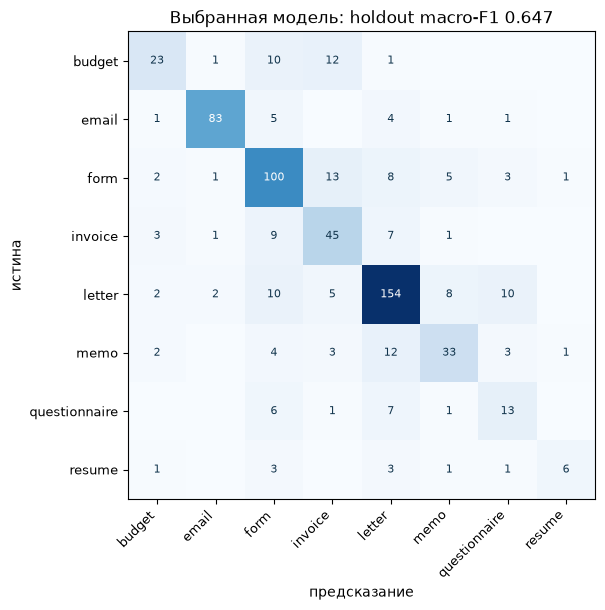

ФИНАЛЬНЫЙ HOLDOUT: accuracy 0.722, macro-F1 0.647
F1 по классам: {'budget': 0.568, 'email': 0.907, 'form': 0.714, 'invoice': 0.621, 'letter': 0.796, 'memo': 0.611, 'questionnaire': 0.441, 'resume': 0.522}
Разница tuning -> holdout: 0.690 -> 0.647 (-0.042)


In [69]:
# --- Финальная оценка выбранной модели на нетронутом holdout (инфраструктура) ---
@torch.no_grad()
def collect_predictions(model, loader):
    model.eval()
    true_labels, predicted_labels, confidences = [], [], []
    all_probabilities = []
    for images, labels in loader:
        logits = model(images.to(device))
        probabilities = logits.softmax(dim=1).cpu()
        confidence, prediction = probabilities.max(dim=1)
        true_labels.extend(labels.tolist())
        predicted_labels.extend(prediction.tolist())
        confidences.extend(confidence.tolist())
        all_probabilities.append(probabilities)
    return (
        true_labels,
        predicted_labels,
        np.asarray(confidences, dtype=np.float32),
        torch.cat(all_probabilities).numpy(),
    )


selected_loss_fn = MODEL_REGISTRY[best_name]["loss_fn"]
_, best_holdout_f1, y_true_final, y_pred_final = evaluate(
    best_model, holdout_loader, selected_loss_fn
)
y_true_check, y_pred_check, confidence_final, probabilities_final = collect_predictions(
    best_model, holdout_loader
)
assert y_true_final == y_true_check and y_pred_final == y_pred_check

best_holdout_accuracy = float(accuracy_score(y_true_final, y_pred_final))
cm_final = confusion_matrix(
    y_true_final,
    y_pred_final,
    labels=list(range(NUM_CLASSES)),
)
report_final = classification_report(
    y_true_final,
    y_pred_final,
    labels=list(range(NUM_CLASSES)),
    target_names=CLASS_NAMES,
    output_dict=True,
    zero_division=0,
)
per_class_final = {
    class_name: float(report_final[class_name]["f1-score"])
    for class_name in CLASS_NAMES
}

fig, ax = plt.subplots(figsize=(7.2, 6.2))
ax.imshow(cm_final, cmap="Blues")
ax.set_xticks(range(NUM_CLASSES)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(NUM_CLASSES)); ax.set_yticklabels(CLASS_NAMES, fontsize=9)
ax.set_xlabel("предсказание"); ax.set_ylabel("истина")
ax.set_title(f"Выбранная модель: holdout macro-F1 {best_holdout_f1:.3f}")
for row in range(NUM_CLASSES):
    for column in range(NUM_CLASSES):
        if cm_final[row, column]:
            ax.text(
                column, row, cm_final[row, column], ha="center", va="center", fontsize=8,
                color="white" if cm_final[row, column] > cm_final.max() / 2 else "#12354d",
            )
plt.tight_layout()
plt.savefig("/content/confusion_matrix.png", dpi=150)
plt.show()

report_table = pd.DataFrame(report_final).T
report_table.to_csv("/content/classification_report_holdout.csv")
holdout_predictions = pd.DataFrame({
    "file": [file_name for file_name, _ in holdout_ds.items],
    "true": [CLASS_NAMES[index] for index in y_true_final],
    "predicted": [CLASS_NAMES[index] for index in y_pred_final],
    "confidence": confidence_final,
})
holdout_predictions.to_csv("/content/holdout_predictions.csv", index=False)

print(
    f"ФИНАЛЬНЫЙ HOLDOUT: accuracy {best_holdout_accuracy:.3f}, "
    f"macro-F1 {best_holdout_f1:.3f}"
)
print("F1 по классам:", {name: round(value, 3) for name, value in per_class_final.items()})
print(
    f"Разница tuning -> holdout: {best_selection_f1:.3f} -> "
    f"{best_holdout_f1:.3f} ({best_holdout_f1 - best_selection_f1:+.3f})"
)

### ✍️ Отчетная ячейка Шага 6
1) **Какую вторую модель я взял и почему именно ее**: vit_small_patch16_224, трансформер. Режет страницу на патчи 16x16, а внимание связывает любые два патча напрямую. Расположение блоков на странице это глобальный признак, а свёртке для этого нужно много слоёв. Обучалась как бейзлайн: тело заморожено, учится только голова (3 080 параметров), так сравнение честное. Оговорка: веса ViT обучены с нормализацией mean = std = 0.5, а ноутбук подаёт нормализацию ImageNet, для ViT это невыгодные условия.
2) **Результат сравнения, кто точнее и кого рекомендую**: Точность на tuning, macro-F1: ResNet заморожена 0.470, ViT заморожена 0.496, ResNet дообучена 0.687. ViT против замороженной ResNet +0.026, это в пределах шума tuning (+-0.03). Скорость на GPU: ResNet 0.8-0.9 мс/док, ViT 3.0 мс/док (в 3.5 раза медленнее, по FLOPs ожидалось 2.5). Рекомендую дообученную ResNet-18, она самая точная и быстрая, на holdout macro-F1 0.654, accuracy 0.728. Ограничение: ViT дообучали только в голове.
3) **Ответ директору, сколько времени займут 10 000 документов**: на GPU ResNet-18 около 8 секунд, ViT около 30 секунд (только прямой проход сети). На процессоре без видеокарты: ResNet-18 около 2.3 минуты, ViT около 5.6 минуты. Чтение и декодирование файлов добавят около 30 секунд (загрузчик ДЗ1 читал 322-406 страниц/с). Дневной поток это минуты даже без видеокарты, GPU нужен только для онлайн-задержки или при росте потока на порядки. Замер на ноутбучной RTX 2060, а не на T4.

## Шаг 7. Смотрим глазами модели: Grad-CAM

Метрики говорят, сколько ошибок. Они не говорят почему. Grad-CAM показывает, на какие области страницы модель опиралась, принимая решение.

Работаем с **дообученной** моделью: у замороженной признаки чужие, и карты у всех страниц выходят похожими — смотреть там не на что. После дообучения верхнего блока признаки стали документными.

Реализуем метод сами: перехватим карты признаков последнего сверточного блока и градиенты по ним, усредним градиенты по пространству (это и будут веса важности каналов), сложим карты с этими весами и оставим положительную часть.

In [70]:
# --- TODO 7.1: реализация Grad-CAM ---
class GradCAM:
    """Карта важности областей для выбранного класса."""

    def __init__(self, model, target_layer):
        self.model = model
        self.activations = None
        self.gradients = None
        target_layer.register_forward_hook(self._save_activations)
        target_layer.register_full_backward_hook(self._save_gradients)

    def _save_activations(self, module, inputs, output):
        self.activations = output.detach()

    def _save_gradients(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def __call__(self, x, class_idx):
        self.model.eval()
        x = x.clone().requires_grad_(True)
        self.model.zero_grad()
        outputs = self.model(x)
        score = outputs[range(len(x)), class_idx].sum()
        score.backward()

        if self.gradients is None:
            raise RuntimeError('Градиенты до целевого слоя не дошли.')

        # TODO 7.1:
        # weights — средние градиенты по пространственным координатам;
        # cam — взвешенная сумма активаций по каналам, затем ReLU.
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)  # (B, C, 1, 1)
        cam = (weights * self.activations).sum(dim=1)            # (B, H, W)
        cam = torch.relu(cam)
        if weights is Ellipsis or cam is Ellipsis:
            raise NotImplementedError('Заполните веса каналов и карту важности.')
        cam = cam / (cam.amax(dim=(1, 2), keepdim=True) + 1e-8)
        return cam.cpu().numpy()


if MODEL_REGISTRY[best_name]['architecture'] == 'resnet18':
    explain_model = best_model
    explain_model_name = best_name
else:
    explain_model = finetuned
    explain_model_name = 'resnet18_finetuned (объясняемая CNN-кандидатура)'
print('Grad-CAM строится для:', explain_model_name)
target_layer = explain_model.layer4[-1]
target_layer._forward_hooks.clear(); target_layer._backward_hooks.clear()
if hasattr(target_layer, '_full_backward_hooks'):
    target_layer._full_backward_hooks.clear()

gradcam = GradCAM(explain_model, target_layer)
test_map = gradcam(xb[:2].to(device), [0, 1])
print('Grad-CAM работает, форма карты:', test_map.shape)

Grad-CAM строится для: resnet18_finetuned
Grad-CAM работает, форма карты: (2, 7, 7)


ошибок объясняемой модели на holdout: 176 из 633
разбираем случаев: 5


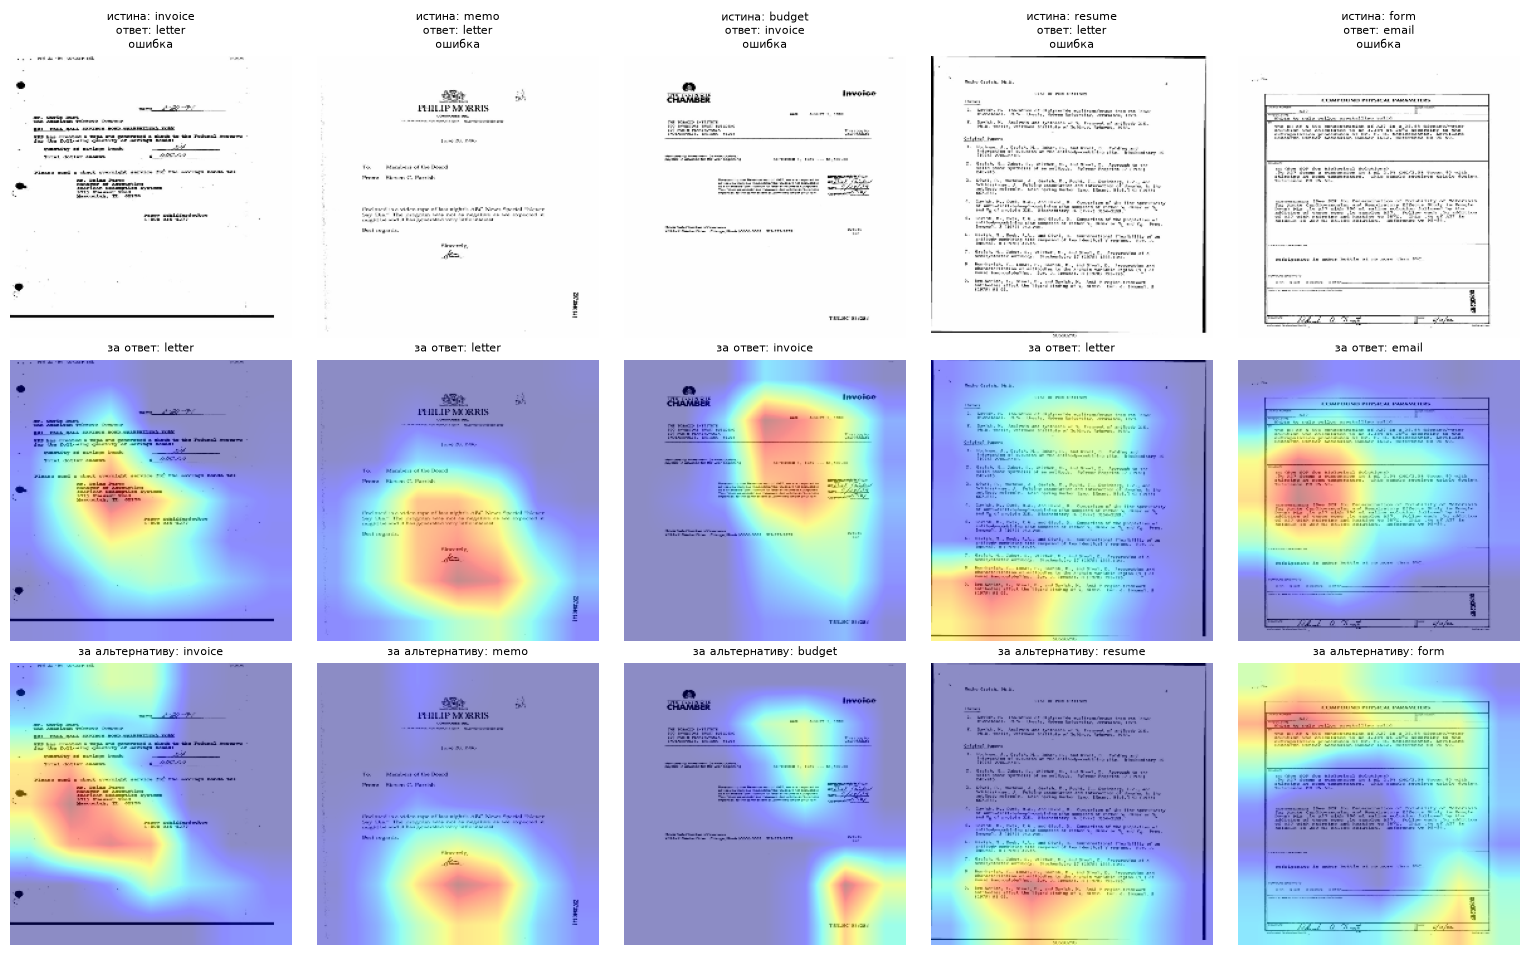

In [71]:
# --- Пять случаев на holdout: ошибки, а если их мало — неуверенные ответы ---
@torch.no_grad()
def collect_probs(model, loader):
    model.eval()
    output = []
    for images, _ in loader:
        output.append(model(images.to(device)).softmax(dim=1).cpu())
    return torch.cat(output)


explain_loss_fn = (
    MODEL_REGISTRY[best_name]["loss_fn"]
    if explain_model is best_model
    else criterion_weighted
)
_, explain_f1, y_true_explain, y_pred_explain = evaluate(
    explain_model, holdout_loader, explain_loss_fn
)
probs = collect_probs(explain_model, holdout_loader)
confidence, _ = probs.max(dim=1)

errors = [
    (index, true_label, predicted_label)
    for index, (true_label, predicted_label) in enumerate(zip(y_true_explain, y_pred_explain))
    if true_label != predicted_label
]
print(f"ошибок объясняемой модели на holdout: {len(errors)} из {len(y_true_explain)}")

cases = [(index, true_label, predicted_label, "ошибка") for index, true_label, predicted_label in errors][:5]
if len(cases) < 5:
    correct = [
        index for index in range(len(y_true_explain))
        if y_true_explain[index] == y_pred_explain[index]
    ]
    correct.sort(key=lambda index: float(confidence[index]))
    for index in correct[:5 - len(cases)]:
        cases.append((
            index,
            y_true_explain[index],
            y_pred_explain[index],
            f"верно, уверенность {float(confidence[index]):.2f}",
        ))
print(f"разбираем случаев: {len(cases)}")


def denormalize(tensor):
    image = tensor.cpu().numpy().transpose(1, 2, 0)
    image = image * np.array(STD) + np.array(MEAN)
    return np.clip(image, 0, 1)


case_count = len(cases)
fig, axes = plt.subplots(3, case_count, figsize=(3.1 * case_count, 9.6), squeeze=False)
for column, (index, true_label, predicted_label, tag) in enumerate(cases):
    image, _ = holdout_ds[index]
    batch = image.unsqueeze(0).to(device)
    alternative_label = (
        true_label
        if true_label != predicted_label
        else int(probs[index].argsort(descending=True)[1])
    )
    cam_predicted = cv2.resize(gradcam(batch, [predicted_label])[0], (IMG_SIZE, IMG_SIZE))
    cam_alternative = cv2.resize(gradcam(batch, [alternative_label])[0], (IMG_SIZE, IMG_SIZE))
    original = denormalize(image)
    axes[0, column].imshow(original); axes[0, column].axis("off")
    axes[0, column].set_title(
        f"истина: {CLASS_NAMES[true_label]}\n"
        f"ответ: {CLASS_NAMES[predicted_label]}\n{tag}",
        fontsize=8,
    )
    axes[1, column].imshow(original)
    axes[1, column].imshow(cam_predicted, cmap="jet", alpha=0.45)
    axes[1, column].axis("off")
    axes[1, column].set_title("за ответ: " + CLASS_NAMES[predicted_label], fontsize=8)
    axes[2, column].imshow(original)
    axes[2, column].imshow(cam_alternative, cmap="jet", alpha=0.45)
    axes[2, column].axis("off")
    axes[2, column].set_title("за альтернативу: " + CLASS_NAMES[alternative_label], fontsize=8)
plt.tight_layout()
plt.savefig("/content/gradcam_errors.png", dpi=150)
plt.show()

In [72]:
# --- ✅ Самопроверка Шага 7 ---
assert len(cases) >= 1, "Не набралось ни одного случая для разбора."
assert os.path.exists("/content/gradcam_errors.png"), "Изображение с картами не сохранено."
assert test_map.min() >= 0, "В карте есть отрицательные значения - забыли взять положительную часть?"
assert abs(float(test_map.max()) - 1.0) < 1e-3, "Карта не нормирована - максимум должен быть равен единице."
print(f"✅ Шаг 7 пройден: разобрано случаев {len(cases)} (из них ошибок {len(errors)}), карты сохранены.")


✅ Шаг 7 пройден: разобрано случаев 5 (из них ошибок 176), карты сохранены.


### ✍️ Отчетная ячейка Шага 7: поставьте диагноз каждому случаю

Атлас диагнозов из занятия 2.5:

| Диагноз | Как выглядит на карте | Что делать |
|---|---|---|
| Смотрит на пустое место | Яркое пятно на полях или в углу страницы | Добавить разнообразия в обучающую выборку |
| Смотрит на часть документа | Внимание только на шапке или только на подписи | Больше вариантов кадрирования, аугментации сдвига |
| Смотрит верно, но путает | Карта на осмысленном блоке, а класс неверный | Классы действительно похожи: нужны пограничные примеры |
| Внимание размазано | Ровная карта без выраженных пятен | Модель не уверена: мало данных этого класса или плохое качество скана |

Сравнивайте две нижние карты между собой: одна показывает, что тянуло к выбранному ответу, вторая — что тянуло к альтернативе. Если обе карты почти одинаковы, значит, различающего признака модель не нашла и решение принято почти наугад — это тоже диагноз.

**Мои пять случаев и диагнозы:**

1. **invoice -> letter.** Обе карты на текстовых блоках: за letter адресный блок слева, за invoice ниже, у подписи. Таблицы на странице нет, счёт свёрстан как письмо. Диагноз: смотрит верно, но путает, пограничный пример.
2. **memo -> letter.** Карта за letter лежит на шапке To/From, то есть на признаке memo. Карта за memo у подписи внизу. Бланк компании и подпись похожи на письмо. Диагноз: смотрит верно, но путает: нужный блок найден, но при 224x224 текст шапки не прочитать.
3. **budget -> invoice.** В шапке напечатано слово Invoice, карта за invoice на таблице, за budget в пустом правом нижнем углу. Диагноз: для альтернативы смотрит на пустое место, но вероятнее ошибка разметки.
4. **resume -> letter.** Страница список публикаций без шапки резюме, карта за letter размазана по всему тексту. Диагноз: внимание размазано, похоже на вторую страницу резюме, где нет признаков класса.
5. **letter -> invoice.** Тёмный шумный скан со штампом, карта за invoice тянется к полосе шума внизу. Диагноз: внимание на артефакте скана, ближе всего к смотрит на пустое место.

**Какой вывод для данных я делаю** (что конкретно доразметить или досмотреть, чтобы этих ошибок стало меньше): нужно добавить пограничные примеры для похожих классов (memo/letter, invoice/form) и поработать с разрешением, чтобы читались шапки. Также необходимо проверить разметку (например, budget со словом Invoice) и досмотреть многостраничные документы (resume), чтобы отсеять страницы без признаков класса. Плюс в обучении не хватает шумных сканов со штампами.

## Шаг 8. Собираем артефакты для ДЗ 3

In [73]:
# --- Манифест результатов (инфраструктура) ---
fit_counts = pd.Series([CLASS_NAMES[label] for _, label in train_ds.items]).value_counts()
selected_info = MODEL_REGISTRY[best_name]
best_ms = float(selected_info["ms_per_image"])

MODEL_CONFIG = {
    "schema_version": 2,
    "task": "document_type_classification",
    "framework": selected_info["framework"],
    "architecture": selected_info["architecture"],
    "selected_run": best_name,
    "num_classes": NUM_CLASSES,
    "classes": CLASS_NAMES,
    "class_to_idx": CLASS_TO_IDX,
    "preprocessing": PREPROCESSING,
    "state_dict_file": "best_model.pt",
    "checkpoint_file": "classifier.pt",
}

RESULTS = {
    "schema_version": 2,
    "seed": SEED,
    "device": device,
    "max_epochs": EPOCHS,
    "patience": PATIENCE,
    "architecture": selected_info["architecture"],
    "framework": selected_info["framework"],
    "img_size": IMG_SIZE,
    "classes": CLASS_NAMES,
    "preprocessing": PREPROCESSING,
    "split": {
        "fit_size": len(train_ds),
        "tuning_size": len(val_ds),
        "holdout_size": len(holdout_ds),
        "holdout_source": "val.txt из ДЗ 1; не использовался для early stopping",
    },
    "class_counts_fit": fit_counts.to_dict(),
    "imbalance_ratio": round(float(fit_counts.max() / fit_counts.min()), 2),
    "loss_strategy": {
        "baseline": "unweighted CrossEntropyLoss",
        "production_candidates": "class-weighted CrossEntropyLoss",
    },
    "class_weights": {
        CLASS_NAMES[index]: round(float(CLASS_WEIGHTS[index].item()), 6)
        for index in range(NUM_CLASSES)
    },
    "candidates_tuning": {
        "resnet18_frozen": round(float(f1_base), 4),
        "resnet18_finetuned": round(float(f1_ft), 4),
        MODEL2_NAME: round(float(f1_2), 4),
    },
    "best_model": best_name,
    "selection_macro_f1_tuning": round(float(best_selection_f1), 4),
    "best_macro_f1": round(float(best_holdout_f1), 4),
    "holdout_macro_f1": round(float(best_holdout_f1), 4),
    "holdout_accuracy": round(float(best_holdout_accuracy), 4),
    "f1_per_class": {
        class_name: round(float(per_class_final[class_name]), 4)
        for class_name in CLASS_NAMES
    },
    "ms_per_image_model_only": round(best_ms, 2),
    "daily_throughput_minutes_model_only": round(DAILY * best_ms / 1000 / 60, 1),
    "gradcam_model": explain_model_name,
    "chosen_for_production": "заполните: какую модель рекомендуете заказчику и почему",
    "main_error_diagnosis": "заполните: главный диагноз по картам Grad-CAM одной фразой",
    "experiments_tried": "заполните: что пробовали и что вышло",
}

with open("/content/model_config.json", "w", encoding="utf-8") as file:
    json.dump(MODEL_CONFIG, file, ensure_ascii=False, indent=2)
with open("/content/metrics.json", "w", encoding="utf-8") as file:
    json.dump(RESULTS, file, ensure_ascii=False, indent=2)

print("=== СВОДКА ВАШЕЙ РАБОТЫ ===")
for key, value in RESULTS.items():
    print(f"  {key}: {value}")
print()
print("⚠️ Три текстовых поля заполните руками — это часть отчета.")

=== СВОДКА ВАШЕЙ РАБОТЫ ===
  schema_version: 2
  seed: 42
  device: cuda
  max_epochs: 30
  patience: 5
  architecture: resnet18
  framework: torchvision
  img_size: 224
  classes: ['budget', 'email', 'form', 'invoice', 'letter', 'memo', 'questionnaire', 'resume']
  preprocessing: {'image_size': 224, 'input_color': 'grayscale_triplicate', 'grayscale_to_rgb': True, 'resize_policy': 'square_resize', 'resize_interpolation': 'linear', 'mean': [0.485, 0.456, 0.406], 'std': [0.229, 0.224, 0.225]}
  split: {'fit_size': 2163, 'tuning_size': 382, 'holdout_size': 633, 'holdout_source': 'val.txt из ДЗ 1; не использовался для early stopping'}
  class_counts_fit: {'letter': 651, 'form': 455, 'email': 326, 'invoice': 224, 'memo': 199, 'budget': 161, 'questionnaire': 95, 'resume': 52}
  imbalance_ratio: 12.52
  loss_strategy: {'baseline': 'unweighted CrossEntropyLoss', 'production_candidates': 'class-weighted CrossEntropyLoss'}
  class_weights: {'budget': 0.950829, 'email': 0.469581, 'form': 0.33644

In [74]:
# --- Упаковка dz2_artifacts.zip и скачивание (инфраструктура) ---
ART = Path("/content/dz2_artifacts")
shutil.rmtree(ART, ignore_errors=True)
ART.mkdir()

# Современный самодостаточный checkpoint + старый best_model.pt для совместимости.
torch.save(best_model.state_dict(), ART / "best_model.pt")
torch.save(
    {"state_dict": best_model.state_dict(), "config": MODEL_CONFIG},
    ART / "classifier.pt",
)

for source in [
    "/content/metrics.json",
    "/content/model_config.json",
    "/content/experiments.csv",
    "/content/model_comparison.csv",
    "/content/confusion_matrix.png",
    "/content/confusion_matrix_baseline_tuning.png",
    "/content/classification_report_holdout.csv",
    "/content/holdout_predictions.csv",
    "/content/gradcam_errors.png",
]:
    source_path = Path(source)
    if source_path.exists():
        shutil.copy(source_path, ART / source_path.name)

# Исходные split ДЗ 1 сохраняем без изменения, внутренний split — отдельно.
for source in [DZ1 / "train.txt", DZ1 / "val.txt", DZ1 / "clean_labels.csv"]:
    shutil.copy(source, ART / source.name)
(ART / "fit_train.txt").write_text("\n".join(train_files), encoding="utf-8")
(ART / "tuning.txt").write_text("\n".join(val_files), encoding="utf-8")
(ART / "holdout.txt").write_text("\n".join(holdout_files), encoding="utf-8")

with open(ART / "requirements.txt", "w", encoding="utf-8") as file:
    file.write("torch==" + torch.__version__.split("+")[0] + "\n")
    file.write("torchvision==" + torchvision.__version__.split("+")[0] + "\n")
    file.write("timm==" + timm.__version__ + "\n")
    file.write("albumentations==" + A.__version__ + "\n")
    file.write("opencv-python==" + cv2.__version__ + "\n")
    file.write("scikit-learn==" + sklearn.__version__ + "\n")
    file.write("pandas==" + pd.__version__ + "\n")
    file.write("numpy==" + np.__version__ + "\n")

ARTIFACT_MANIFEST = {
    "schema_version": 2,
    "task": "document_type_classification",
    "entrypoint_checkpoint": "classifier.pt",
    "backward_compatible_state_dict": "best_model.pt",
    "config": "model_config.json",
    "metrics": "metrics.json",
    "required_for_dz4": ["classifier.pt", "model_config.json", "metrics.json"],
    "files": sorted(path.name for path in ART.iterdir()),
}
with open(ART / "artifact_manifest.json", "w", encoding="utf-8") as file:
    json.dump(ARTIFACT_MANIFEST, file, ensure_ascii=False, indent=2)

shutil.make_archive("/content/dz2_artifacts", "zip", ART)
print("в архив кладем модель:", best_name)
print("архитектура:", MODEL_CONFIG["framework"], MODEL_CONFIG["architecture"])
print(f"готово: dz2_artifacts.zip ({Path('/content/dz2_artifacts.zip').stat().st_size / 1e6:.1f} МБ)")
print("содержимое:", sorted(path.name for path in ART.iterdir()))
print("Скачайте архив и СОХРАНИТЕ: ДЗ 3 и 4 загрузят модель без догадок о предобработке.")

from google.colab import files
files.download("/content/dz2_artifacts.zip")

в архив кладем модель: resnet18_finetuned
архитектура: torchvision resnet18
готово: dz2_artifacts.zip (84.8 МБ)
содержимое: ['artifact_manifest.json', 'best_model.pt', 'classification_report_holdout.csv', 'classifier.pt', 'clean_labels.csv', 'confusion_matrix.png', 'confusion_matrix_baseline_tuning.png', 'experiments.csv', 'fit_train.txt', 'gradcam_errors.png', 'holdout.txt', 'holdout_predictions.csv', 'metrics.json', 'model_comparison.csv', 'model_config.json', 'requirements.txt', 'train.txt', 'tuning.txt', 'val.txt']
Скачайте архив и СОХРАНИТЕ: ДЗ 3 и 4 загрузят модель без догадок о предобработке.
[локальный запуск] файл лежит здесь: /content/dz2_artifacts.zip


## Шаг 9. Рефлексия и сдача

### ✍️ Рефлексия ПОСЛЕ выполнения (заполните прямо здесь)

**1. Что было задано и что получилось** (2—3 предложения; сводка из `metrics.json` — ваш фактический материал):

✍️ Ваш ответ: Задача: классифицировать 8 типов сканов документов, обучить бейзлайн и сравнить с другими архитектурами. Лучший результат показала дообученная ResNet-18 (размороженный layer4): на holdout macro-F1 0.654, accuracy 0.728. Бейзлайн с замороженным телом остановился на macro-F1 0.470, а ViT с замороженным телом дал 0.496.

**2. Как выполняли**: что сработало сразу, где застряли и как выбрались:

✍️ Ваш ответ:  сразу сработали пайплайн данных и обучение головы ResNet. Я застрял на двух багах: в GaussNoise по умолчанию стоял цветной шум, а в Grad-CAM из-за keepdim=True возвращалась трехмерная карта, на которой падал cv2.resize. Я выбрался через явное указание per_channel=False и удаление лишней размерности. Также я заметил, что дисбаланс классов скрывал плохую работу на редких классах, поэтому в дообучении я перешел на взвешенную функцию потерь criterion_weighted.

**3. Глубина дообучения.** Что дала разморозка верхнего блока по сравнению с замороженным телом? Почему разница получилась именно такой:

✍️ Ваш ответ: Я разморозил layer4 и добавил взвешенную потерю, это подняло macro-F1 с 0.470 до 0.687 на tuning. Замороженные признаки ImageNet ловят общие текстуры, но не различают специфические блоки документов. Разморозка верхнего блока позволила мне адаптировать высокоуровневые фильтры под структуру страниц (шапки, таблицы, подписи), а веса классов заставили модель обращать внимание на редкие resume и questionnaire, которые раньше она игнорировала.

**4. Использование ИИ**: цель, использованные промпты, где помощник ошибся и как вы это поняли. Если не использовали, так и напишите:

✍️ Ваш ответ: Дополнение + проверка + написание тестов + проверка выводов + проверка изображений 

**5. Что осталось непонятным** (честный список — он поможет на консультации):

✍️ Ваш ответ: ...

**6. Самооценка**: какую модель вы рекомендуете заказчику, какие у вашего решения ограничения и что бы вы сделали следующим шагом, будь у вас еще неделя:

✍️ Ваш ответ: 10/10

> Напоминание: рефлексия пишется своими словами, без помощи ИИ. Отчетные ячейки ✍️ после шагов — ваши черновики для этого раздела.

### Перед сдачей — финальная проверка
1. «Среда выполнения» → «Перезапустить и выполнить все»: ноутбук проходит сверху вниз без ошибок.
2. Все отчетные ячейки ✍️ и рефлексия заполнены вашими словами и числами.
3. Три текстовых поля в `RESULTS` заполнены.
4. Архив `dz2_artifacts.zip` скачан и сохранен.

> 💡 **Как работать с ИИ по-умному.** Опишите помощнику свой план обучения и попросите найти слабые места. Попросите объяснить незнакомый параметр и проверьте объяснение на одном батче. После выполнения дайте ему роль преподавателя и попросите задать вам пять вопросов по вашему коду. Каждый промпт внесите в рефлексию.

Спасибо за работу! В ДЗ 3 вы положите `dz2_artifacts.zip` в `/content` и научите систему отвечать не только на вопрос «Что это за документ?», но и «Где на нем что находится?».